<a href="https://colab.research.google.com/github/Nonamechick/AI-Electronic-Khasan/blob/main/DecisionTree.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, GridSearchCV, KFold
from sklearn.tree import DecisionTreeRegressor, plot_tree
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
url = "https://raw.githubusercontent.com/victor4friend-eng/data_pub/refs/heads/main/decision_t_data1.csv"
data = pd.read_csv(url)
data.head()


,x,y
0,0.773956,0.631174
1,0.438878,0.172884
2,0.858598,0.736934
3,0.697368,0.478150
4,0.094177,0.025748


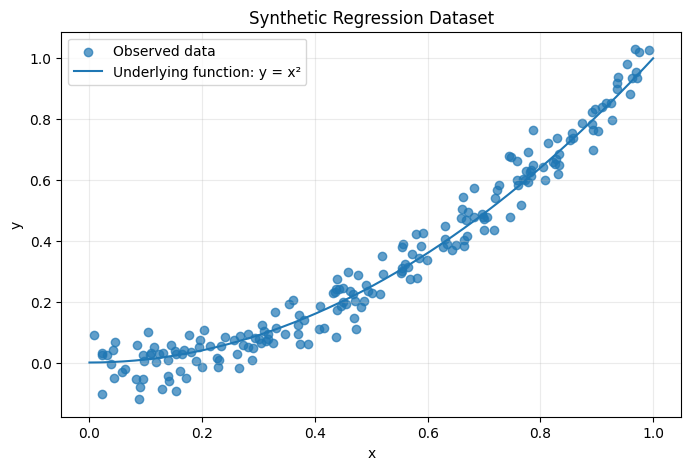

In [3]:
X = data[["x"]].values
y = data["y"].values

plt.figure(figsize=(8, 5))
plt.scatter(X.ravel(), y, alpha=0.7, label="Observed data")
x_line = np.linspace(0, 1, 200)
plt.plot(x_line, x_line**2, label="Underlying function: y = x²")
plt.xlabel("x")
plt.ylabel("y")
plt.title("Synthetic Regression Dataset")
plt.legend()
plt.grid(alpha=0.25)
plt.show()


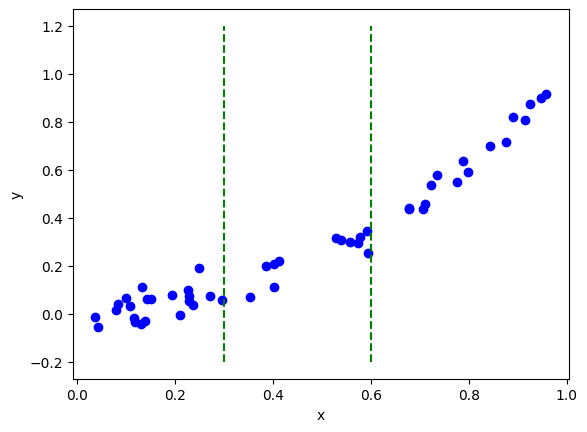

In [4]:
X = np.random.sample(50)
Y = np.array([x**2 + np.random.normal(0, 0.05) for x in X])

plt.xlabel("x")
plt.ylabel("y")

plt.scatter(X, Y, color='b')
plt.plot([0.3, 0.3], [-0.2, 1.2], 'g--')
plt.plot([0.6, 0.6], [-0.2, 1.2], 'g--');


In [6]:
def avg(X, Y, x_min, x_max):
  """Return the average value in (x_min, x_max) range"""
  n = 0    # number of samples in given split
  avg = 0  # average value

  for x, y in zip(X, Y):
    if x >= x_min and x < x_max:
      n += 1
      avg += y

  return avg / n



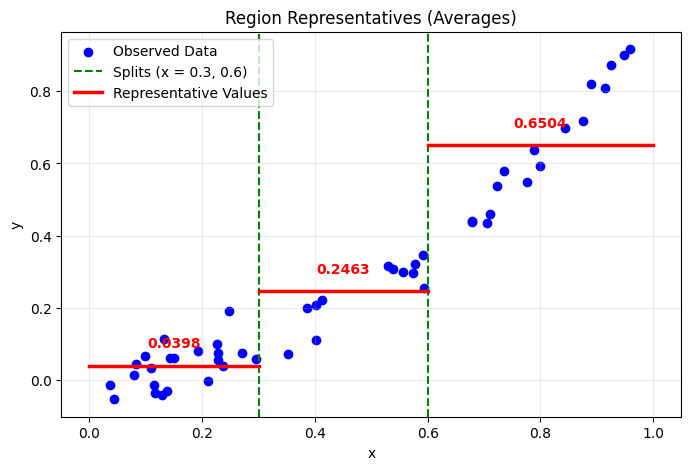

In [10]:
plt.figure(figsize=(8, 5))
plt.scatter(X, Y, color='b', label='Observed Data')

# Split boundaries
plt.axvline(x=0.3, color='g', linestyle='--', label='Splits (x = 0.3, 0.6)')
plt.axvline(x=0.6, color='g', linestyle='--')

# Compute averages
y1 = avg(X, Y, 0.0, 0.3)
y2 = avg(X, Y, 0.3, 0.6)
y3 = avg(X, Y, 0.6, 1.0)

# Plot representatives
plt.plot([0.0, 0.3], [y1, y1], 'r-', linewidth=2.5, label='Representative Values')
plt.plot([0.3, 0.6], [y2, y2], 'r-', linewidth=2.5)
plt.plot([0.6, 1.0], [y3, y3], 'r-', linewidth=2.5)

# Text annotations on graph
plt.text(0.15, y1 + 0.05, f'{y1:.4f}', color='red', weight='bold', ha='center')
plt.text(0.45, y2 + 0.05, f'{y2:.4f}', color='red', weight='bold', ha='center')
plt.text(0.80, y3 + 0.05, f'{y3:.4f}', color='red', weight='bold', ha='center')

plt.xlabel("x")
plt.ylabel("y")
plt.title("Region Representatives (Averages)       Xasan")
plt.legend(loc='upper left')
plt.grid(alpha=0.25)
plt.show()

In [9]:
avg_1 = avg(X, Y, 0.0, 0.3)
avg_2 = avg(X, Y, 0.3, 0.6)
avg_3 = avg(X, Y, 0.6, 1.0)

print(f"Representative value (Average) for Region 1 [0.0, 0.3): {avg_1:.4f}")
print(f"Representative value (Average) for Region 2 [0.3, 0.6): {avg_2:.4f}")
print(f"Representative value (Average) for Region 3 [0.6, 1.0]: {avg_3:.4f}")

Representative value (Average) for Region 1 [0.0, 0.3): 0.0398
Representative value (Average) for Region 2 [0.3, 0.6): 0.2463
Representative value (Average) for Region 3 [0.6, 1.0]: 0.6504
